# Conflated Play Prediction: Markov Chain + Classifier

Per Sections 4.2-4.3 of the Smart Stadium paper, play-type prediction combines two independent signals:

1. **Markov Chain (MC)**: predicts the upcoming play's type from its game context, using no video at all.
2. **A play-type classifier** (in the paper, a CNN over video clips) that predicts play type directly from a single clip, with no game context.

These are **conflated** (entry-wise multiplication of the two probability vectors, then renormalized) because they make independent kinds of mistakes: the classifier can be fooled by a bad clip, while the MC has no idea what's actually happening on the field. The paper's Figure 11 also learns per-class correction weights on top of the raw product (`fit_conflation_weights`).

**What's new in this version (v2):**

- The MC is trained on **real NCAA play-by-play** (cfbfastR, 2017 season) instead of simulated games. `playByPlay.py` loads and cleans it.
- The MC predicts from the **upcoming play's pre-snap situation**: down, distance to go, field zone, the offense's run tendency, and game situation (score + clock). v1 used the *previous* play's `(down, play_type, field_bucket)`, which turned out to be much less predictive (section 4).
- Rare situations **back off** to coarser ones instead of getting near-uniform probabilities, so more markers don't need a bigger dataset.

**v2.1** adds `prefilter_plays`, which drops or repairs the few hundred plays with impossible pre-snap fields before training and testing (section 1).

The original toy-data version is preserved in `archive/v1_markov_chain/`.

**Still simulated:** the classifier. Its probabilities are a noisy stand-in until the video pipeline produces real ones (section 5).

In [1]:
import sys
from pathlib import Path
# make the repo root importable whether Jupyter starts in the repo root or in notebooks/
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'conflation.py').exists())
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from playByPlay import load_cfb_pbp, download_cfb_pbp, PLAY_CODES
from markovChain import PlayMarkovChain, MARKERS, prefilter_plays
from conflation import conflate_probabilities, fit_conflation_weights
from archive.v1_markov_chain.markovChain import PlayMarkovChain as PlayMarkovChainV1

CLASSIFIER_PLAY_TYPES = ('R', 'P', 'F', 'U', 'O')  # run, pass, field goal, punt, other
FOCUS_TEAM = 'Georgia Tech'
rng = np.random.default_rng(7)

## 1. Load real play-by-play data

Source: the cfbfastR play-by-play release on GitHub (`sportsdataverse-data`, tag `cfbfastR_cfb_pbp`), one parquet file per season from 2014 on. No API key needed. `download_cfb_pbp` fetches a season into `data/cfb_pbp/` (gitignored) if it isn't there yet.

`load_cfb_pbp` drops non-plays (timeouts, end of period), maps cfbfastR's ~40 play-type labels to our codes, and adds `prev_play_type`. Two things worth knowing about the labels:

- **PATs aren't separate rows** in this data (they're folded into the touchdown play), so there's no PAT code.
- **"Penalty" rows are sorted by their text**: most are a real run or pass wiped out by the flag; the rest are pre-snap fouls where no play happened, which make up nearly all of the **"other" (O)** class. Roughing the passer and intentional grounding count as passes, and penalties on kickoffs as kickoffs.
- **Fumble return touchdowns are dropped**: they repeat the play before them (often a sack whose text leaves out the fumble) rather than being a new snap.

`prefilter_plays` (new in v2.1) then drops or repairs the few hundred plays whose pre-snap fields are impossible: down 0, a snap on a goal line, a missing distance, or a distance past the goal line. Goal-to-go plays with a blank distance get their distance from `yards_to_goal`.


In [2]:
path = download_cfb_pbp(2017, ROOT / 'data' / 'cfb_pbp')
plays, prefilter_counts = prefilter_plays(load_cfb_pbp(path), report=True)  # drop or repair impossible plays
print(f'{len(plays)} plays from {plays.game_id.nunique()} games after prefiltering')
print(prefilter_counts)
print()
print(plays.play_type.value_counts().rename(index=PLAY_CODES).to_string())
plays.head()

149546 plays from 869 games after prefiltering
{'dropped: down not 1-4': 2, 'dropped: yards_to_goal not 1-99': 160, 'dropped: no distance outside goal-to-go': 146, 'repaired: goal-to-go distance': 189, 'repaired: distance past the goal line': 39}

play_type
run                                        64567
pass (incl. sacks and interceptions)       59765
kickoff                                     9621
punt                                        8898
other (pre-snap foul / no play, safety)     4091
field goal                                  2604


,game_id,play_number,season,week,offense,defense,period,half,seconds_left_half,down,distance,yards_to_goal,score_diff,play_type,prev_play_type,raw_play_type
0,400933827,1,2017,1,Alabama,Florida State,1,1,1800.0,1,10.0,65.0,0.0,K,S,Kickoff
1,400933827,2,2017,1,Alabama,Florida State,1,1,1792.0,1,10.0,75.0,0.0,R,K,Rush
2,400933827,3,2017,1,Alabama,Florida State,1,1,1768.0,1,10.0,41.0,0.0,P,R,Pass Incompletion
3,400933827,4,2017,1,Alabama,Florida State,1,1,1762.0,2,10.0,41.0,0.0,R,P,Rush
4,400933827,5,2017,1,Alabama,Florida State,1,1,1729.0,3,5.0,36.0,0.0,P,R,Pass Reception


## 2. Fit the Markov Chain on a training split of games

Whole games go to either train or test, so the test games are completely unseen. The team-tendency marker uses each offense's run rate from the **training games only**.

In [3]:
games = plays.game_id.unique()
test_games = set(rng.permutation(games)[: len(games) // 5])
is_test = plays.game_id.isin(test_games)
train = plays[~is_test]
test = plays[is_test & plays.play_type.isin(CLASSIFIER_PLAY_TYPES)]  # kickoffs aren't a classifier class
print(f'{train.game_id.nunique()} train games, {len(test_games)} test games, '
      f'{len(test)} test plays ({(test.offense == FOCUS_TEAM).sum()} by {FOCUS_TEAM})')

mc = PlayMarkovChain().fit(train)

finest = mc.counts[-1]
seen = sum(n.sum() for n in finest.values())
well_covered = sum(n.sum() for n in finest.values() if n.sum() >= 10)
print(f'\nmarkers: {mc.markers}')
print(f'{mc.n_contexts} possible contexts, {len(finest)} seen in training, '
      f'{sum(n.sum() >= 10 for n in finest.values())} with >= 10 plays '
      f'({well_covered / seen:.1%} of training plays are in those)')

696 train games, 173 test games, 27857 test plays (242 by Georgia Tech)



markers: ('down', 'distance', 'field_zone', 'team_tendency', 'game_situation')
1200 possible contexts, 1061 seen in training, 649 with >= 10 plays (98.3% of training plays are in those)


## 3. What the model predicts

The same situations for a run-heavy offense (Georgia Tech's option, 81% runs in 2017) and a pass-heavy one (Washington State's air raid). Down and distance drive most of the prediction; team tendency shifts run vs. pass.

In [4]:
print({team: round(mc.run_rates[team], 2) for team in (FOCUS_TEAM, 'Washington State')})

situations = {
    '1st & 10, own 25':               dict(down=1, distance=10, yards_to_goal=75, score_diff=0, half=1, period=1, seconds_left_half=1500),
    '3rd & 8, own 35':                dict(down=3, distance=8, yards_to_goal=65, score_diff=0, half=1, period=2, seconds_left_half=600),
    '4th & 2, opp 30':                dict(down=4, distance=2, yards_to_goal=30, score_diff=0, half=2, period=3, seconds_left_half=1200),
    '4th & 9, own 30':                dict(down=4, distance=9, yards_to_goal=70, score_diff=3, half=2, period=3, seconds_left_half=1100),
    '2nd & 10, down 7, 3 min left':   dict(down=2, distance=10, yards_to_goal=60, score_diff=-7, half=2, period=4, seconds_left_half=180),
}
rows = []
for name, situation in situations.items():
    for team in (FOCUS_TEAM, 'Washington State'):
        proba = mc.next_play_type_proba({**situation, 'offense': team}, play_types=CLASSIFIER_PLAY_TYPES)
        rows.append({'situation': name, 'offense': team, **dict(zip(CLASSIFIER_PLAY_TYPES, proba.round(3)))})
pd.DataFrame(rows).set_index(['situation', 'offense'])

{'Georgia Tech': 0.79, 'Washington State': 0.26}


R      P      F      U  \
situation                    offense                                        
1st & 10, own 25             Georgia Tech      0.715  0.263  0.000  0.000   
                             Washington State  0.459  0.518  0.000  0.000   
3rd & 8, own 35              Georgia Tech      0.282  0.694  0.000  0.002   
                             Washington State  0.110  0.844  0.000  0.000   
4th & 2, opp 30              Georgia Tech      0.390  0.245  0.329  0.033   
                             Washington State  0.211  0.463  0.256  0.007   
4th & 9, own 30              Georgia Tech      0.005  0.011  0.000  0.943   
                             Washington State  0.000  0.010  0.000  0.949   
2nd & 10, down 7, 3 min left Georgia Tech      0.516  0.462  0.000  0.000   
                             Washington State  0.239  0.751  0.000  0.000   

                                                   O  
situation                    offense                  
1st & 10, own 25             Georgia Tech      0.023  
                             Washington State  0.023  
3rd & 8, own 35              Georgia Tech      0.022  
                             Washington State  0.046  
4th & 2, opp 30              Georgia Tech      0.003  
                             Washington State  0.063  
4th & 9, own 30              Georgia Tech      0.041  
                             Washington State  0.041  
2nd & 10, down 7, 3 min left Georgia Tech      0.022  
                             Washington State  0.010

## 4. Compare with the archived v1 model

v1 (`archive/v1_markov_chain/`) predicts the next play from the **previous** play's `(down, play_type, field_bucket)`. Trained on the same games, it's compared on the same test plays. Log loss rewards well-calibrated probabilities (lower is better), which matters because conflation uses the whole probability vector, not just the top guess.

In [5]:
def v1_state(down, play_type, yards_to_goal):
    return (int(down), play_type, int(min(9, (100 - yards_to_goal) // 10)))

v1 = PlayMarkovChainV1()
v1.fit([[v1_state(*row) for row in game[['down', 'play_type', 'yards_to_goal']].itertuples(index=False)]
        for _, game in train.groupby('game_id')])

prev = plays.groupby('game_id')[['down', 'play_type', 'yards_to_goal']].shift(1).loc[test.index]
uniform = np.full(len(CLASSIFIER_PLAY_TYPES), 1 / len(CLASSIFIER_PLAY_TYPES))
P_v1 = np.array([uniform if pd.isna(row.play_type) else
                 v1.next_play_type_proba(v1_state(row.down, row.play_type, row.yards_to_goal), play_types=CLASSIFIER_PLAY_TYPES)
                 for row in prev.itertuples()])
P_v2 = mc.predict_proba(test, play_types=CLASSIFIER_PLAY_TYPES)

overall_rates = train.play_type.value_counts().reindex(CLASSIFIER_PLAY_TYPES, fill_value=0).values + 1.0
P_prior = np.tile(overall_rates / overall_rates.sum(), (len(test), 1))

y = test.play_type.map({t: i for i, t in enumerate(CLASSIFIER_PLAY_TYPES)}).values
focus = (test.offense == FOCUS_TEAM).values

def scores(P, mask):
    return {'log loss': -np.log(P[mask, y[mask]]).mean(), 'accuracy': (P[mask].argmax(1) == y[mask]).mean()}

mc_results = pd.DataFrame({
    (subset, metric): {name: scores(P, mask)[metric] for name, P in
                       [('overall rates only', P_prior), ('v1 MC', P_v1), ('v2 MC', P_v2)]}
    for subset, mask in [('all plays', np.ones(len(y), bool)), (f'{FOCUS_TEAM} offense', focus)]
    for metric in ('log loss', 'accuracy')
})
mc_results.round(3)

all plays          Georgia Tech offense         
                    log loss accuracy             log loss accuracy
overall rates only     1.073    0.464                1.024    0.773
v1 MC                  0.869    0.547                0.890    0.678
v2 MC                  0.720    0.653                0.605    0.810

## 5. Conflate with a classifier

**Placeholder:** there's no video classifier output yet, so this simulates one: the true class gets a logit boost of 1.7 on top of Gaussian noise, which makes it about 71% accurate on its own, close to the paper's CNN (75.3%). Replace `simulate_classifier_output` with real CNN probabilities when the video pipeline produces them.

Conflation weights are learned on a sample of training plays. `fit_conflation_weights` is a pure-Python loop, so it uses 2,000 plays rather than all ~110k.

`conflate_probabilities` raises each source's probabilities to at least `floor` (default 1e-4) before multiplying, so a class one source rules out can still win if the other source is confident enough. It's a safeguard for a real CNN, which can be overconfident; with this simulated classifier it doesn't change accuracy.


In [6]:
def simulate_classifier_output(play_types, strength=1.7):
    logits = rng.normal(0, 1, size=(len(play_types), len(CLASSIFIER_PLAY_TYPES)))
    logits[np.arange(len(play_types)), [CLASSIFIER_PLAY_TYPES.index(t) for t in play_types]] += strength
    exp = np.exp(logits - logits.max(axis=1, keepdims=True))
    return exp / exp.sum(axis=1, keepdims=True)

# learn per-class weights on training plays
weight_plays = train[train.play_type.isin(CLASSIFIER_PLAY_TYPES)].sample(2000, random_state=7)
weight_samples = list(zip(simulate_classifier_output(weight_plays.play_type),
                          mc.predict_proba(weight_plays, play_types=CLASSIFIER_PLAY_TYPES),
                          [CLASSIFIER_PLAY_TYPES.index(t) for t in weight_plays.play_type]))
weights = fit_conflation_weights(weight_samples, len(CLASSIFIER_PLAY_TYPES), epochs=300, lr=0.5)
print('learned per-class weights:', dict(zip(CLASSIFIER_PLAY_TYPES, weights.round(3))))

P_clf = simulate_classifier_output(test.play_type)
conflated_v1 = np.array([conflate_probabilities([c, m]) for c, m in zip(P_clf, P_v1)])
conflated_v2 = np.array([conflate_probabilities([c, m]) for c, m in zip(P_clf, P_v2)])
conflated_v2_weighted = np.array([conflate_probabilities([c, m], class_weights=weights) for c, m in zip(P_clf, P_v2)])

predictions = {
    'classifier alone': P_clf,
    'v1 MC alone': P_v1,
    'v2 MC alone': P_v2,
    'conflated with v1 MC': conflated_v1,
    'conflated with v2 MC': conflated_v2,
    'conflated with v2 MC (learned weights)': conflated_v2_weighted,
}
results = pd.DataFrame({
    'all plays': {name: (P.argmax(1) == y).mean() for name, P in predictions.items()},
    f'{FOCUS_TEAM} offense': {name: (P[focus].argmax(1) == y[focus]).mean() for name, P in predictions.items()},
})
results.round(3)

learned per-class weights: {'R': np.float64(1.078), 'P': np.float64(1.045), 'F': np.float64(0.852), 'U': np.float64(0.813), 'O': np.float64(1.28)}


,all plays,Georgia Tech offense
classifier alone,0.709,0.698
v1 MC alone,0.547,0.678
v2 MC alone,0.653,0.810
conflated with v1 MC,0.848,0.864
conflated with v2 MC,0.873,0.893
conflated with v2 MC (learned weights),0.873,0.901


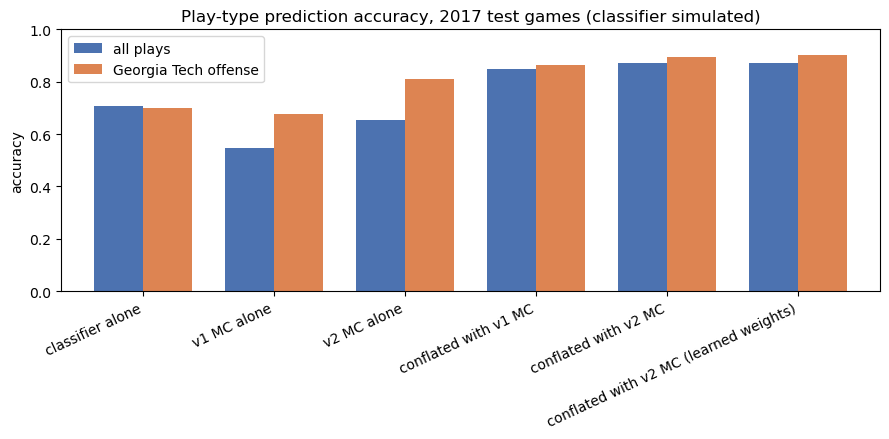

In [7]:
ax = results.plot.bar(figsize=(9, 4.5), color=['#4c72b0', '#dd8452'], width=0.75)
ax.set_ylabel('accuracy')
ax.set_title('Play-type prediction accuracy, 2017 test games (classifier simulated)')
ax.set_ylim(0, 1)
plt.xticks(rotation=25, ha='right')
plt.tight_layout()
plt.show()

## 6. Which markers earn their place (5-fold cross-validation)

The comparison behind the v2 design, rerun on the full season. Every game is in the test set exactly once (5 folds, split by game), and each model is refit on the other 80% of games, including its team run rates. Scores are pooled over all folds: about 140k plays overall and about 840 Georgia Tech plays.

The candidates:

- **Building up:** start from down + distance + field zone and add one marker at a time.
- **Dropping one:** remove each default marker in turn, to see how much each contributes.
- **Alternative buckets:** coarser distance, finer field position, and score and clock as two separate markers instead of one combined game-situation marker. These are defined here as extra entries in `MARKERS`, which is also how to try a new marker.

Takes about 2 minutes.

In [8]:
from bisect import bisect_right
from markovChain import Marker, DEFAULT_MARKERS, LATE_GAME_SECONDS

def is_late(play):
    return play['half'] == 2 and play['period'] <= 4 and play['seconds_left_half'] <= LATE_GAME_SECONDS

def game_situation_3(play, model):
    situation = MARKERS['game_situation'].bucket(play, model)
    return 0 if situation == 3 else situation  # treat end of 1st half as normal

def score_and_clock(play, model):
    return bisect_right((-8, 9), play['score_diff']) * 2 + is_late(play)

# alternative bucketings, registered so PlayMarkovChain can use them by name
MARKERS['distance_3'] = Marker(('1-3', '4-7', '8+'), lambda play, model: bisect_right((4, 8), play['distance']))
MARKERS['field_zone_10'] = Marker(tuple(f'own {10 * i}-{10 * i + 9}' for i in range(10)),
                                  lambda play, model: min(9, int(100 - play['yards_to_goal']) // 10))
MARKERS['game_situation_3'] = Marker(('normal', 'trailing late', 'leading late'), game_situation_3)
MARKERS['score_and_clock'] = Marker(tuple(f'{score}, {clock}' for score in ('down 9+', 'within 8', 'up 9+')
                                          for clock in ('not late', 'late')), score_and_clock)

def swap(old, new):
    return tuple(new if m == old else m for m in DEFAULT_MARKERS)

BASE = ('down', 'distance', 'field_zone')
candidates = {
    'overall rates only': (),
    'down + distance + field zone': BASE,
    '  + team tendency': BASE + ('team_tendency',),
    '  + game situation  (v2 default)': DEFAULT_MARKERS,
    '  + previous play type': DEFAULT_MARKERS + ('prev_play_type',),
    'default without down': tuple(m for m in DEFAULT_MARKERS if m != 'down'),
    'default without distance': tuple(m for m in DEFAULT_MARKERS if m != 'distance'),
    'default without field zone': tuple(m for m in DEFAULT_MARKERS if m != 'field_zone'),
    'default without team tendency': tuple(m for m in DEFAULT_MARKERS if m != 'team_tendency'),
    'default without game situation': BASE + ('team_tendency',),
    '3 distance buckets (1-3/4-7/8+)': swap('distance', 'distance_3'),
    '10 field-position buckets': swap('field_zone', 'field_zone_10'),
    'game situation w/o end of 1st half': swap('game_situation', 'game_situation_3'),
    'score and clock as separate markers': swap('game_situation', 'score_and_clock'),
}

In [9]:
cv_rng = np.random.default_rng(0)
fold_of_game = dict(zip(games, cv_rng.permutation(len(games)) % 5))
fold = plays.game_id.map(fold_of_game).values
is_target = plays.play_type.isin(CLASSIFIER_PLAY_TYPES).values
prev_rows = plays.groupby('game_id')[['down', 'play_type', 'yards_to_goal']].shift(1)

def v1_predict(train_plays, test_plays):
    model = PlayMarkovChainV1()
    model.fit([[v1_state(*row) for row in game[['down', 'play_type', 'yards_to_goal']].itertuples(index=False)]
               for _, game in train_plays.groupby('game_id')])
    return np.array([uniform if pd.isna(row.play_type) else
                     model.next_play_type_proba(v1_state(row.down, row.play_type, row.yards_to_goal),
                                                play_types=CLASSIFIER_PLAY_TYPES)
                     for row in prev_rows.loc[test_plays.index].itertuples()])

def cross_validate(predict):
    # predict(train_plays, test_plays) -> probabilities; returns log loss and accuracy pooled over 5 folds
    neg_log, hits, is_focus = [], [], []
    for f in range(5):
        train_plays, test_plays = plays[fold != f], plays[(fold == f) & is_target]
        P = predict(train_plays, test_plays)
        y_fold = test_plays.play_type.map({t: i for i, t in enumerate(CLASSIFIER_PLAY_TYPES)}).values
        neg_log.append(-np.log(P[np.arange(len(y_fold)), y_fold]))
        hits.append(P.argmax(1) == y_fold)
        is_focus.append((test_plays.offense == FOCUS_TEAM).values)
    neg_log, hits, is_focus = map(np.concatenate, (neg_log, hits, is_focus))
    return {'log loss': neg_log.mean(), 'accuracy': hits.mean(),
            f'{FOCUS_TEAM} log loss': neg_log[is_focus].mean(), f'{FOCUS_TEAM} accuracy': hits[is_focus].mean()}

def markov_predict(markers, **kwargs):
    return lambda train_plays, test_plays: PlayMarkovChain(markers, **kwargs).fit(train_plays).predict_proba(
        test_plays, play_types=CLASSIFIER_PLAY_TYPES)

cv_results = {'v1 MC (archived)': {'contexts': 280, **cross_validate(v1_predict)}}
for name, markers in candidates.items():
    cv_results[name] = {'contexts': PlayMarkovChain(markers).n_contexts, **cross_validate(markov_predict(markers))}
cv_results = pd.DataFrame(cv_results).T.astype({'contexts': int})
cv_results.round(3)

,contexts,log loss,accuracy,Georgia Tech log loss,Georgia Tech accuracy
v1 MC (archived),280,0.867,0.544,0.819,0.673
overall rates only,1,1.073,0.461,1.021,0.727
down + distance + field zone,100,0.750,0.620,0.715,0.717
+ team tendency,300,0.741,0.630,0.589,0.794
+ game situation (v2 default),1200,0.720,0.649,0.566,0.805
+ previous play type,8400,0.719,0.654,0.565,0.805
default without down,300,0.965,0.546,0.815,0.726
default without distance,240,0.752,0.620,0.621,0.771
default without field zone,240,0.765,0.629,0.610,0.789
default without team tendency,400,0.725,0.643,0.694,0.718


**Reading the table** (2017 season):

- **Down matters most.** Dropping it costs far more than any other marker (log loss 0.720 → 0.965), then field zone (→ 0.765), distance (→ 0.752) and game situation (→ 0.741).
- **Team tendency is small overall but large for option teams.** Across all plays it only moves log loss 0.725 → 0.720, but for Georgia Tech it's the biggest single marker (0.694 → 0.566, accuracy 71.8% → 80.5%).
- **Previous play type isn't worth it.** It multiplies the contexts by 7 (1,200 → 8,400) for a 0.001 log-loss gain, which is why it's optional rather than a default.
- **The chosen buckets beat the alternatives.** 5 distance buckets beat 3 (0.720 vs 0.725). The end-of-1st-half value helps (0.720 vs 0.725 without it). Combining score and clock into one marker beats keeping them separate (0.720 vs 0.729, with fewer contexts). 10 field buckets are no better than 5 (0.723), at twice the contexts.
- **v1 is worse than knowing only down, distance and field zone** (0.867 vs 0.750), because it conditions on the previous play's situation rather than the upcoming one.

The back-off strength `k` controls how many plays a context needs before its own rates outweigh the coarser context's. Results are flat between about 5 and 50 (10 and 25 tie on log loss); the default is 25.

In [10]:
pd.DataFrame({k: cross_validate(markov_predict(DEFAULT_MARKERS, backoff_strength=k))
              for k in (1, 5, 10, 25, 50, 100)}).T.rename_axis('backoff_strength').round(4)

,log loss,accuracy,Georgia Tech log loss,Georgia Tech accuracy
backoff_strength,,,,
1,0.7271,0.6515,0.5701,0.8009
5,0.7212,0.6516,0.5654,0.8045
10,0.7199,0.6512,0.5648,0.8045
25,0.7199,0.6494,0.5664,0.8045
50,0.7216,0.6472,0.5705,0.8021
100,0.7248,0.6460,0.5786,0.7950


## Notes and next steps

- **Real classifier:** the conflated numbers depend on the simulated classifier. Rerun section 5 with real CNN probabilities once they exist.
- **"Other" class:** in this data, O is almost entirely pre-snap fouls. If the video labels use "other" for something else (ads, replays), the MC shouldn't be asked to predict it.
- **Team tendency source:** here it comes from the training games of the same season. For predicting a live season, pass last season's rates: `PlayMarkovChain().fit(plays, run_rates=team_run_rates(last_season_plays))`.
- **More data:** `load_cfb_pbp` accepts a list of files, e.g. 2014-2017, and 2016 matches some of the project's video clips.
- **Markers:** `PlayMarkovChain(markers=...)` takes any subset/order of `MARKERS`; add `'prev_play_type'` to restore the classic Markov dependence on the previous play.